In [28]:
from utils.JetGraphProducer import JetGraphProducer
from utils.ConeGraphProducer import ConeGraphProducer
from utils.LundTreeUtilities import OnTheFlyNormalizer
import torch

# Produce the graphs. The call to JetGraphProducer will produce the graphs and
# save them in the specified directory if it is not already present.
jet_cone = ConeGraphProducer(
        "data/", # Path to the directory containing the root files to be processed
        "jet_cone_test", # Name to be given to the produced dataset (or the name of the dataset if it is already present)
        n_store_jets=1, # Number of jets to process per event, in order of decreasing pT
        delta_r_threshold=0.2, # Threshold for the deltaR distance between constituents to be considered connected
        n_store_cands=20, # Number of constituents to store per jet (spacial graphs only)
        # max_events_to_process=100, # Maximum number of events to process (set to None to process all events)
        save_edge_attributes=False, # Whether to save the edge attributes (pairwise invariant masses, Cambridge-Aachen and kt distances)
        save_n_constituents=False, # Whether to save the number of constituents in the graph
        save_event_number=False, # Whether to save the event number in the graph
        use_lund_decomp=False, # Whether to use the Lund decomposition
        weights="xsec", # Weights to be applied to the graphs (None, "xsec")
        save_jet_idx=False, # Whether to save the jet index
        label=0., # Label to add to the graph for supervised learning
        verbose=True, # Whether to print the progress of the processing
    )

jet_classic = JetGraphProducer(
    "data/", # Path to the directory containing the root files to be processed
        "jet_cone_test", # Name to be given to the produced dataset (or the name of the dataset if it is already present)
        n_store_jets=1, # Number of jets to process per event, in order of decreasing pT
        delta_r_threshold=0.2, # Threshold for the deltaR distance between constituents to be considered connected
        n_store_cands=20, # Number of constituents to store per jet (spacial graphs only)
        # max_events_to_process=100, # Maximum number of events to process (set to None to process all events)
        save_edge_attributes=False, # Whether to save the edge attributes (pairwise invariant masses, Cambridge-Aachen and kt distances)
        save_n_constituents=False, # Whether to save the number of constituents in the graph
        save_event_number=False, # Whether to save the event number in the graph
        use_lund_decomp=False, # Whether to use the Lund decomposition
        weights="xsec", # Weights to be applied to the graphs (None, "xsec")
        save_jet_idx=False, # Whether to save the jet index
        label=0., # Label to add to the graph for supervised learning
        verbose=True, # Whether to print the progress of the processing
)

/work/kfuss/SVJ_GNN/utils/ConeGraphProducer.py:150: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.data, self.slices = torch.load(self.processed_paths[0])
/work/kfuss/SV

In [29]:
print(jet_cone[0])
print(type(jet_cone[0]))

Data(x=[55, 12], edge_index=[2, 108], y=[1], num_node_features=[1], w=[1], num_nodes=55)
<class 'torch_geometric.data.data.Data'>


In [30]:
from torch_geometric.utils import to_networkx
import matplotlib.pyplot as plt
import networkx as nx

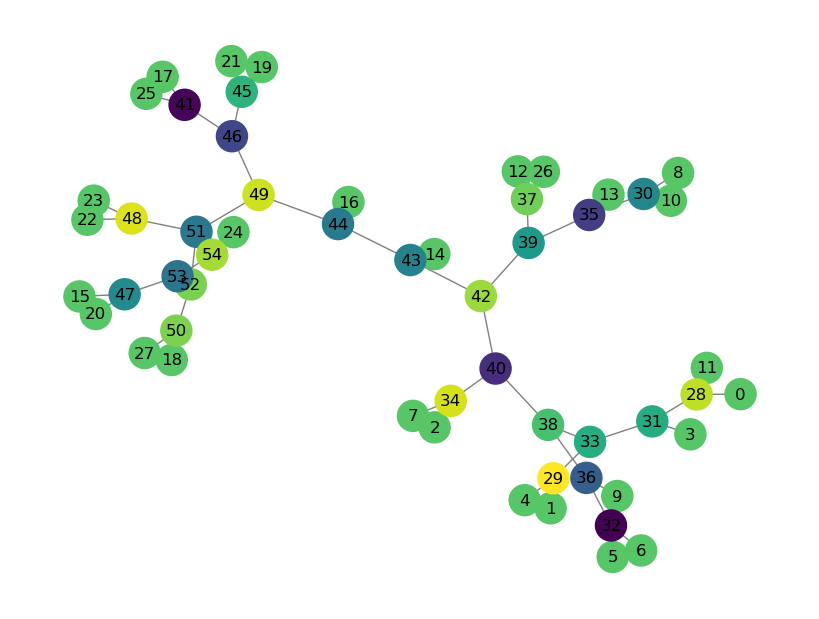

In [31]:
# Assume `data` is your torch_geometric.data.Data object
G_cone = to_networkx(jet_cone[0], to_undirected=True)
# nx.spring_layout(G, seed=42)

# Optional: use different numbers for different particles
node_color = jet_cone[0].x[:, 3].numpy()

plt.figure(figsize=(8, 6))
nx.draw(G_cone, with_labels=True, node_color=node_color, edge_color='gray', node_size=500)
plt.show()

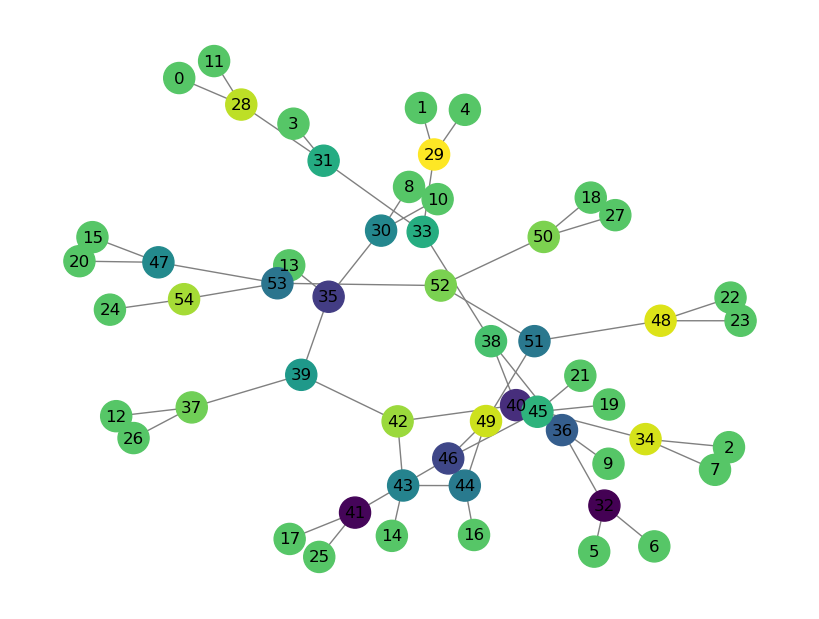

In [32]:
# Assume `data` is your torch_geometric.data.Data object
G_classic = to_networkx(jet_classic[0], to_undirected=True)
# nx.spring_layout(G, seed=42)

# Optional: use different numbers for different particles
node_color = jet_classic[0].x[:, 3].numpy()

plt.figure(figsize=(8, 6))
nx.draw(G_classic, with_labels=True, node_color=node_color, edge_color='gray', node_size=500)
plt.show()